# 06 — Logistic Regression: train, tune and interpret

**Start here after Notebooks 01–05.** Select the project `.venv` kernel, then **Restart Kernel and Run All**. You do not need to run `06_model_training_and_evaluation.ipynb` or any research model notebook first. Keep `pricecatcher_config.py` and `prepare.py` beside this notebook. If a package is missing, install `requirements.txt` in the selected kernel and restart.

**Question:** can tuning regularisation and class weighting improve Logistic Regression over its reference settings and simple baselines?

**One model, one workflow:** verify the completed holdout preparation from 05 → prepare missing 2025 folds if safe → compare reference settings and Optuna trials → select by mean fold AP → fit through December 2025 → select a cutoff on January–March 2026 validation → save model, predictions, tables and plots.

**Declared search:** 16 sequential Optuna trials; `C` from 0.001 to 10 on a log scale; `class_weight` either `None` or `"balanced"`; fixed L2 regularisation and at most 2,000 iterations. The four queued references are C=0.1 and C=1 with and without balancing. Every trial uses all three expanding folds, with no pruning or SMOTE. Maximise mean sklearn average precision (AP); earliest trial breaks ties. AP is not accuracy or trapezoidal PR-AUC. Trials may repeat configurations.

**Evaluation status:** earlier validation and April–June 2026 test results have already been inspected. Restarting from 05 does not make these periods untouched. This is a reorganised exploratory/reproduction workflow, not a fresh final test. No test rows or November outcomes are loaded here. The 10% price-rise label and classifier score cutoff are separate.

Each execution saves a separate timestamped folder under `06_logistic_regression/` inside the active data run. It does not replace existing models or dashboard inputs. Read section 1 for implementation, sections 4–6 for results and plots, and section 7 for report guidance.

## 1. Technique and settings

Logistic Regression learns a linear score and applies a sigmoid:

$$s(x)=\frac{1}{1+\exp[-(\beta_0+\beta^Tx)]}.$$

Inputs describe the completed current week and past history. Numerical features are median-imputed, missing indicators are added, and values are scaled. Categorical features are one-hot encoded; unknown categories are ignored. All learned preprocessing is fitted inside each training fold.

| Parameter | Values tested | Why it matters |
|---|---|---|
| `C` | 0.001–10, logarithmic sampling | Smaller C gives stronger L2 regularisation and coefficient shrinkage. |
| `class_weight` | `None`, `"balanced"` | Equal observation weights versus weights derived from that fit's training class frequencies. |

L2 regularisation, solver defaults, maximum 2,000 iterations and seed 42 stay fixed. No validation labels determine training weights. Scores are uncalibrated, including when no weighting is used. More tuning does not guarantee better later-period performance. Convergence warnings stop execution rather than silently ranking an unconverged fit.

In [1]:
import sys
from pathlib import Path
REPOSITORY_ROOT = Path.cwd()
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent
if not (REPOSITORY_ROOT / "pricecatcher_config.py").is_file():
    raise FileNotFoundError("Open the FYP project folder before running this notebook.")
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

import hashlib
import json
import warnings
from datetime import datetime, timezone
from importlib import metadata, reload
from time import perf_counter
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import optuna
except ModuleNotFoundError:
    raise ModuleNotFoundError("Install Optuna in this kernel: %pip install 'optuna>=4,<5', then restart and Run All.") from None
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import pricecatcher_config as cfg
cfg = reload(cfg)

SEED = 42
N_TRIALS = 16
MAX_ITER = 2000
REFERENCE_SETTINGS = [
    ("Reference C=0.1", 0.1, "balanced"),
    ("Reference C=1", 1.0, "balanced"),
    ("Unweighted C=0.1", 0.1, None),
    ("Unweighted C=1", 1.0, None),
]
FOLDS = ["fold_1", "fold_2", "fold_3"]
print("Python:", sys.executable)
print("Prepared run:", cfg.PROJECT_ROOT)
print("Trials:", N_TRIALS, "| Folds:", len(FOLDS), "| Fixed target: 10%")

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /usr/local/bin/python3.12
Prepared run: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240
Trials: 16 | Folds: 3 | Fixed target: 10%


## 2. Continue the preparation from Notebook 05

The holdout train/validation inputs must already exist. They are never regenerated here. Existing complete expanding folds are reused. If a fold is absent, the existing `prepare.py` runs only preparation notebooks for that fold, using the verified local source; it does not train the old comparison models.

Partial fold inputs and missing inputs belonging to saved experiments stop execution rather than being overwritten. Restore a matching completed snapshot or start a deliberate new preparation from 01 if needed. The helper still applies item eligibility and cleaning rules using each fold's training period. This avoids deriving early-fold filters from all of 2025.

In [2]:
def file_hash(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

folders = {name: cfg.PROJECT_ROOT / "experiments" / name / "05_modelling"
           for name in FOLDS + ["holdout"]}
input_paths = [folder / filename for folder in folders.values()
               for filename in ["experiment_settings.json", "train.parquet", "validation.parquet"]]
# A manual Run All in 01–05 normally prepares holdout only.
required_names = ["experiment_settings.json", "train.parquet", "validation.parquet"]
holdout_missing = [str(folders["holdout"] / name) for name in required_names
                   if not (folders["holdout"] / name).is_file()]
if holdout_missing:
    raise FileNotFoundError("Complete Notebook 05 first. Missing: " + ", ".join(holdout_missing))
holdout_hashes = {name: file_hash(folders["holdout"] / name) for name in required_names}
missing_folds = [name for name in FOLDS
                 if not all((folders[name] / filename).is_file() for filename in required_names)]
if missing_folds:
    partial_folds = [name for name in missing_folds
                     if folders[name].exists() and any(folders[name].iterdir())]
    saved_models = any((folder / "best_model.joblib").exists() for folder in cfg.MODEL_DIRS)
    saved_studies = (any(cfg.PROJECT_ROOT.glob("*_optuna/*/study_manifest.json"))
                     or any((cfg.PROJECT_ROOT / "06_logistic_regression").glob("*/study_manifest.json")))
    if partial_folds or saved_models or saved_studies:
        raise FileNotFoundError(
            f"Incomplete folds: {missing_folds}. Restore their matching prepared inputs; "
            "partial inputs or saved experiments are present. To reproduce from source, start a separate run with 01–05.")
    if not (REPOSITORY_ROOT / "prepare.py").is_file():
        raise FileNotFoundError("Keep prepare.py beside this notebook; it prepares missing chronological folds.")
    cfg.verify_source_snapshot()
    import os
    import subprocess
    for name in missing_folds:
        print("Preparing chronological inputs (no model training):", name, flush=True)
        subprocess.run([sys.executable, str(REPOSITORY_ROOT / "prepare.py"), "--experiment", name],
                       cwd=REPOSITORY_ROOT,
                       env={**os.environ, "PRICECATCHER_DATA_DIR": str(cfg.PROJECT_ROOT)}, check=True)
if any(file_hash(folders["holdout"] / name) != digest for name, digest in holdout_hashes.items()):
    raise ValueError("Holdout preparation changed during fold preparation. Stop and restore the matching snapshot.")
missing = [str(path) for path in input_paths if not path.is_file()]
if missing:
    raise FileNotFoundError("Preparation did not produce the required files: " + ", ".join(missing))
input_hashes = {str(path.relative_to(cfg.PROJECT_ROOT)): file_hash(path) for path in input_paths}
settings_by_fold = {name: json.loads((folder / "experiment_settings.json").read_text())
                    for name, folder in folders.items()}
settings = settings_by_fold["holdout"]
FEATURES = settings["feature_columns"]
NUMERIC = settings["numeric_features"]
CATEGORICAL = settings["categorical_features"]
if len(FEATURES) != len(set(FEATURES)) or sorted(NUMERIC + CATEGORICAL) != sorted(FEATURES):
    raise ValueError("Numeric and categorical features must partition the feature list.")
if any(c.startswith("next_") or c in ["surge_label", "split"] for c in FEATURES):
    raise ValueError("Future outcomes must not enter the model features.")
if settings["surge_threshold_pct"] != 10:
    raise ValueError("This study requires the existing fixed 10% target.")
variable = {"experiment", "train_end", "validation_end", "test_end", "evaluation_end",
            "apply_documented_exclusions", "source_manifest_sha256", "source_snapshot_sha256"}
policy = {k: v for k, v in settings["preparation"].items() if k not in variable}
source_key = ("source_snapshot_sha256" if settings["preparation"].get("source_snapshot_sha256")
              else "source_manifest_sha256")
source_id = settings["preparation"].get(source_key)
if not source_id:
    raise ValueError("Source identity is missing; restore matching preparation metadata.")

frames = {}
for name, folder in folders.items():
    s = settings_by_fold[name]
    if tuple(s[k] for k in ["train_end", "validation_end", "test_end"]) != tuple(cfg.EXPERIMENTS[name]):
        raise ValueError(f"{name}: date settings differ from the configured chronological experiment.")
    for key in ["feature_columns", "numeric_features", "categorical_features", "target_status", "surge_threshold_pct"]:
        if s[key] != settings[key]:
            raise ValueError(f"{name}: incompatible {key}.")
    if ({k: v for k, v in s["preparation"].items() if k not in variable} != policy
            or s["preparation"].get(source_key) != source_id
            or s["preparation"].get("experiment") != name):
        raise ValueError(f"{name}: shared source/policies differ. Restore consistent prepared inputs.")
    if name in FOLDS and s["preparation"].get("apply_documented_exclusions"):
        raise ValueError("Early folds must retain retrospective exceptions whose review dates are unknown.")
    frames[name] = {}
    for split in ["train", "validation"]:
        frame = pd.read_parquet(folder / f"{split}.parquet")
        required = FEATURES + ["surge_label", "week_start", "next_week_end", "project_group"]
        if frame.empty or set(required) - set(frame.columns):
            raise ValueError(f"{name}/{split}: empty or incomplete input.")
        if frame.surge_label.isna().any() or not frame.surge_label.isin([0, 1]).all() or frame.surge_label.nunique() != 2:
            raise ValueError(f"{name}/{split}: overall evaluation requires both observed classes.")
        for col in ["week_start", "next_week_end"]:
            frame[col] = pd.to_datetime(frame[col])
        if (frame[["week_start", "next_week_end"]].isna().any().any()
                or not frame.week_start.dt.dayofweek.eq(0).all()
                or not frame.next_week_end.eq(frame.week_start + pd.Timedelta(days=13)).all()):
            raise ValueError(f"{name}/{split}: invalid calendar-week horizons.")
        upper = pd.Timestamp(s["train_end" if split == "train" else "validation_end"])
        if not frame.next_week_end.le(upper).all():
            raise ValueError(f"{name}/{split}: outcome crosses its time boundary.")
        if split == "validation" and not (frame.week_start + pd.Timedelta(days=6)).gt(pd.Timestamp(s["train_end"])).all():
            raise ValueError(f"{name}: validation overlaps training.")
        if frame.duplicated(["item_code", "state", "district", "premise_type", "week_start"]).any():
            raise ValueError(f"{name}/{split}: duplicate local series/week.")
        if np.isinf(frame[NUMERIC].to_numpy(dtype=float)).any():
            raise ValueError(f"{name}/{split}: infinite numeric input.")
        frames[name][split] = frame

display(pd.DataFrame([{"experiment": name, "train_end": s["train_end"],
                      "validation_end": s["validation_end"],
                      "training_rows": len(frames[name]["train"]),
                      "validation_rows": len(frames[name]["validation"])}
                     for name, s in settings_by_fold.items()]))

,experiment,train_end,validation_end,training_rows,validation_rows
0,fold_1,2025-05-31,2025-07-31,66384,31971
1,fold_2,2025-07-31,2025-09-30,101515,31753
2,fold_3,2025-09-30,2025-12-31,138296,54666
3,holdout,2025-12-31,2026-03-31,195664,43594


## 3. One readable pipeline and shared metrics

The current-change baseline ranks by the observed weekly percentage change and alerts at 10%, following the saved label tolerance. The no-surge baseline always predicts zero. Classification metrics for fold comparisons use 0.5 for every Logistic Regression setting; AP selects `C` and class weighting independently of that cutoff. Undefined positive-case metrics are left missing for groups without surges; precision is recorded as zero when no alerts are issued.

In [3]:
def model_inputs(frame):
    X = frame[FEATURES].copy()
    for column in CATEGORICAL:
        X[column] = X[column].astype("string").fillna("__missing__").astype(str)
    return X


def build_pipeline(C, class_weight):
    numeric = Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
        ("scale", StandardScaler()),
    ])
    preprocessing = ColumnTransformer([
        ("numeric", numeric, NUMERIC),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=True), CATEGORICAL),
    ], sparse_threshold=1.0)
    return Pipeline([("preprocess", preprocessing),
                     ("model", LogisticRegression(C=C, class_weight=class_weight,
                         max_iter=MAX_ITER, random_state=SEED))])


def fit_and_score(C, class_weight, training, evaluation):
    pipeline = build_pipeline(C, class_weight)
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        pipeline.fit(model_inputs(training), training.surge_label.astype(int))
    scores = pipeline.predict_proba(model_inputs(evaluation))[:, 1]
    if not np.isfinite(scores).all() or not ((scores >= 0) & (scores <= 1)).all():
        raise ValueError("Model scores must be finite and in [0, 1].")
    return pipeline, scores


def evaluate(y, scores, predictions):
    y, scores, predictions = np.asarray(y, dtype=int), np.asarray(scores), np.asarray(predictions, dtype=int)
    if not len(y) or len(y) != len(scores) or len(y) != len(predictions) or not np.isfinite(scores).all():
        raise ValueError("Metrics require aligned nonempty arrays and finite scores.")
    tn, fp, fn, tp = confusion_matrix(y, predictions, labels=[0, 1]).ravel()
    return {"rows": len(y), "positives": int(y.sum()), "alerts": int(predictions.sum()),
            "average_precision": float(average_precision_score(y, scores)) if len(np.unique(y)) == 2 else np.nan,
            "precision": float(precision_score(y, predictions, zero_division=0)),
            "recall": float(recall_score(y, predictions, zero_division=0)) if y.sum() else np.nan,
            "f1": float(f1_score(y, predictions, zero_division=0)) if y.sum() else np.nan,
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


def baselines(frame):
    change = frame.weekly_price_change_pct.to_numpy(dtype=float)
    if not np.isfinite(change).all():
        raise ValueError("Current-change baseline requires supported previous-week prices.")
    tolerance = settings["preparation"].get("label_tolerance_pct", 0.0)
    alerts = (change >= 10) | np.isclose(change, 10, atol=tolerance, rtol=0)
    return {"Always no surge": (np.zeros(len(frame)), np.zeros(len(frame), dtype=int)),
            "Current-change rule": (change, alerts.astype(int))}

## 4. Tune `C` and class weighting with Optuna on the 2025 folds

Optuna's seeded TPE sampler proposes `C` and class weighting together. The objective is the unweighted mean AP across folds; there is no random cross-validation or test evaluation. The first two trials reproduce the original balanced settings; the next two use the same `C` values without weighting. `none` in CSV tables means Python `None`; this label avoids losing unweighted rows when grouping tables. A higher best search score alone is not independent evidence of improvement: the search explicitly selects that score.

If convergence fails, execution stops instead of ranking an unconverged candidate. Inspect the warning; any revised iteration limit must apply to reference and tuned settings alike.

In [4]:
trial_fold_rows = []

def objective(trial):
    C = trial.suggest_float("C", 0.001, 10.0, log=True)
    class_weight = trial.suggest_categorical("class_weight", [None, "balanced"])
    aps = []
    for name in FOLDS:
        training, evaluation = frames[name]["train"], frames[name]["validation"]
        started = perf_counter()
        pipeline, scores = fit_and_score(C, class_weight, training, evaluation)
        metrics = evaluate(evaluation.surge_label, scores, scores >= 0.5)
        trial_fold_rows.append({"trial": trial.number, "C": C, "class_weight": class_weight or "none", "fold": name,
                               "fit_and_score_seconds": perf_counter() - started, **metrics})
        aps.append(metrics["average_precision"])
        del pipeline
    return float(np.mean(aps))

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.NopPruner())
for label, C, class_weight in REFERENCE_SETTINGS:
    study.enqueue_trial({"C": C, "class_weight": class_weight})
study.optimize(objective, n_trials=N_TRIALS, n_jobs=1)
best_trial = max(study.trials, key=lambda trial: (trial.value, -trial.number))
BEST_C = best_trial.params["C"]
BEST_CLASS_WEIGHT = best_trial.params["class_weight"]
trial_folds = pd.DataFrame(trial_fold_rows)
trial_summary = trial_folds.groupby(["trial", "C", "class_weight"], as_index=False).agg(
    mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
    mean_f1_at_05=("f1", "mean"), mean_precision_at_05=("precision", "mean"),
    mean_recall_at_05=("recall", "mean"))
display(trial_summary.sort_values(["mean_ap", "trial"], ascending=[False, True]))
print("Selected C:", BEST_C, "| Class weighting:", BEST_CLASS_WEIGHT, "| Mean fold AP:", best_trial.value)

comparison_rows = []
reference_trials = [(label, number) for number, (label, _, _) in enumerate(REFERENCE_SETTINGS)]
for label, trial_number in reference_trials + [("Optuna selected", best_trial.number)]:
    for row in trial_fold_rows:
        if row["trial"] == trial_number:
            comparison_rows.append({"method": label, **row})
for name in FOLDS:
    evaluation = frames[name]["validation"]
    for label, (scores, predictions) in baselines(evaluation).items():
        comparison_rows.append({"method": label, "fold": name,
                                **evaluate(evaluation.surge_label, scores, predictions)})
fold_comparison = pd.DataFrame(comparison_rows)
fold_summary = fold_comparison.groupby("method").agg(
    mean_ap=("average_precision", "mean"), std_ap=("average_precision", "std"),
    mean_precision=("precision", "mean"), mean_recall=("recall", "mean"), mean_f1=("f1", "mean"))
display(fold_summary)

[I 2026-10-27 17:28:45,332] A new study created in memory with name: no-name-b9a8e9b4-ddd4-499b-aae9-42ed4afb4fc5
[I 2026-10-27 17:28:48,221] Trial 0 finished with value: 0.2939278174355959 and parameters: {'C': 0.1, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.2939278174355959.
[I 2026-10-27 17:28:51,133] Trial 1 finished with value: 0.29601481769744437 and parameters: {'C': 1.0, 'class_weight': 'balanced'}. Best is trial 1 with value: 0.29601481769744437.
[I 2026-10-27 17:28:53,425] Trial 2 finished with value: 0.29618840099829996 and parameters: {'C': 0.1, 'class_weight': None}. Best is trial 2 with value: 0.29618840099829996.
[I 2026-10-27 17:28:55,473] Trial 3 finished with value: 0.3018494868554403 and parameters: {'C': 1.0, 'class_weight': None}. Best is trial 3 with value: 0.3018494868554403.
[I 2026-10-27 17:28:57,215] Trial 4 finished with value: 0.2900789960991377 and parameters: {'C': 0.03148911647956861, 'class_weight': None}. Best is trial 3 with value: 0.30

,trial,C,class_weight,mean_ap,std_ap,mean_f1_at_05,mean_precision_at_05,mean_recall_at_05
11,11,7.553504,none,0.303335,0.031596,0.034037,0.561904,0.017790
10,10,7.536365,none,0.303178,0.032101,0.034488,0.563244,0.018069
15,15,3.639603,none,0.303108,0.032331,0.034550,0.563590,0.018127
13,13,8.879908,none,0.303083,0.031762,0.034558,0.553840,0.018138
12,12,9.176269,none,0.303072,0.031878,0.034155,0.563269,0.017929
14,14,3.494207,none,0.302916,0.031612,0.034970,0.558059,0.018360
8,8,2.136833,none,0.302907,0.031908,0.034270,0.558500,0.017974
3,3,1.000000,none,0.301849,0.031827,0.032619,0.551556,0.017050
5,5,0.248104,none,0.299563,0.031944,0.027512,0.559061,0.014255
2,2,0.100000,none,0.296188,0.033885,0.022882,0.566606,0.011778


Selected C: 7.553503645583189 | Class weighting: None | Mean fold AP: 0.3033346370881529


,mean_ap,std_ap,mean_precision,mean_recall,mean_f1
method,,,,,
Always no surge,0.106114,0.010602,0.000000,0.000000,0.000000
Current-change rule,0.120974,0.026823,0.189686,0.193252,0.191330
Optuna selected,0.303335,0.031596,0.561904,0.017790,0.034037
Reference C=0.1,0.293928,0.029512,0.276557,0.533688,0.342540
Reference C=1,0.296015,0.028935,0.279305,0.541355,0.347246
Unweighted C=0.1,0.296188,0.033885,0.566606,0.011778,0.022882
Unweighted C=1,0.301849,0.031827,0.551556,0.017050,0.032619


## 5. Separate exploratory validation: January–March 2026

Fit each Logistic Regression setting on the same training rows through December 2025. Compare AP and classification metrics at the common 0.5 reference cutoff. This validation period has already been inspected in earlier work; do not treat it as a fresh test.

Also choose an F1-maximising cutoff for the Optuna candidate on this validation period, breaking ties with the highest cutoff. Its resulting classification metrics are **apparent cutoff-selection performance**, not an independent estimate. Do not select the best model again using this table. The saved candidate is not promoted to the dashboard.

In [5]:
training = frames["holdout"]["train"]
validation = frames["holdout"]["validation"]
validation_rows = []
validation_scores = {}
for label, C, class_weight in REFERENCE_SETTINGS + [("Optuna selected", BEST_C, BEST_CLASS_WEIGHT)]:
    pipeline, scores = fit_and_score(C, class_weight, training, validation)
    validation_scores[label] = scores
    validation_rows.append({"method": label, "C": C, "class_weight": class_weight or "none", "cutoff": 0.5,
                            **evaluate(validation.surge_label, scores, scores >= 0.5)})
    if label == "Optuna selected":
        selected_pipeline = pipeline
for label, (scores, predictions) in baselines(validation).items():
    validation_rows.append({"method": label, **evaluate(validation.surge_label, scores, predictions)})
selected_scores = validation_scores["Optuna selected"]
precision, recall, cutoffs = precision_recall_curve(validation.surge_label, selected_scores)
f1 = np.divide(2 * precision[:-1] * recall[:-1], precision[:-1] + recall[:-1],
               out=np.zeros(len(cutoffs)), where=(precision[:-1] + recall[:-1]) > 0)
selected_cutoff = float(cutoffs[np.flatnonzero(np.isclose(f1, f1.max(), atol=1e-12, rtol=0))[-1]])
validation_rows.append({"method": "Optuna selected: apparent cutoff-selection performance",
                        "C": BEST_C, "class_weight": BEST_CLASS_WEIGHT or "none", "cutoff": selected_cutoff,
                        **evaluate(validation.surge_label, selected_scores, selected_scores >= selected_cutoff)})
validation_comparison = pd.DataFrame(validation_rows)
display(validation_comparison)
group_rows = []
for group, positions in validation.groupby("project_group", sort=True).indices.items():
    group_rows.append({"project_group": group,
        **evaluate(validation.iloc[positions].surge_label, selected_scores[positions],
                    selected_scores[positions] >= selected_cutoff)})
group_comparison = pd.DataFrame(group_rows)
display(group_comparison)
print("These group metrics also reuse the cutoff-selection period, not an untouched test.")

,method,C,class_weight,cutoff,rows,positives,alerts,average_precision,precision,recall,f1,tp,fp,fn,tn
0,Reference C=0.1,0.100000,balanced,0.500000,43594,3912,15117,0.244492,0.201561,0.778885,0.320248,3047,12070,865,27612
1,Reference C=1,1.000000,balanced,0.500000,43594,3912,14986,0.245563,0.202989,0.777607,0.321939,3042,11944,870,27738
2,Unweighted C=0.1,0.100000,none,0.500000,43594,3912,1187,0.245007,0.278012,0.084356,0.129437,330,857,3582,38825
3,Unweighted C=1,1.000000,none,0.500000,43594,3912,1264,0.248253,0.280854,0.090746,0.137172,355,909,3557,38773
4,Optuna selected,7.553504,none,0.500000,43594,3912,1275,0.248489,0.283137,0.092280,0.139194,361,914,3551,38768
5,Always no surge,NaN,NaN,NaN,43594,3912,0,0.089737,0.000000,0.000000,0.000000,0,0,3912,39682
6,Current-change rule,NaN,NaN,NaN,43594,3912,4417,0.101561,0.175685,0.198364,0.186337,776,3641,3136,36041
7,Optuna selected: apparent cutoff-selection per...,7.553504,none,0.210914,43594,3912,7772,0.248489,0.261194,0.518916,0.347484,2030,5742,1882,33940


,project_group,rows,positives,alerts,average_precision,precision,recall,f1,tp,fp,fn,tn
0,Chicken,4884,25,0,0.036461,0.000000,0.000000,0.000000,0,0,25,4859
1,Cooking Oil,2178,1,0,0.002151,0.000000,0.000000,0.000000,0,0,1,2177
2,Eggs,8892,53,0,0.025616,0.000000,0.000000,0.000000,0,0,53,8839
3,Flour,1110,15,0,0.038037,0.000000,0.000000,0.000000,0,0,15,1095
4,Rice,384,2,0,1.000000,0.000000,0.000000,0.000000,0,0,2,382
5,Sugar,1837,0,0,NaN,0.000000,NaN,NaN,0,0,0,1837
6,Vegetables,24309,3816,7772,0.255510,0.261194,0.531971,0.350362,2030,5742,1786,14751


These group metrics also reuse the cutoff-selection period, not an untouched test.


## 6. Plots and saved evidence

The plots show search behaviour and validation ranking. The horizontal prevalence reference represents constant-score AP. No plot establishes future reliability. Each new execution saves a separate study; interrupted executions do not publish a completed manifest.

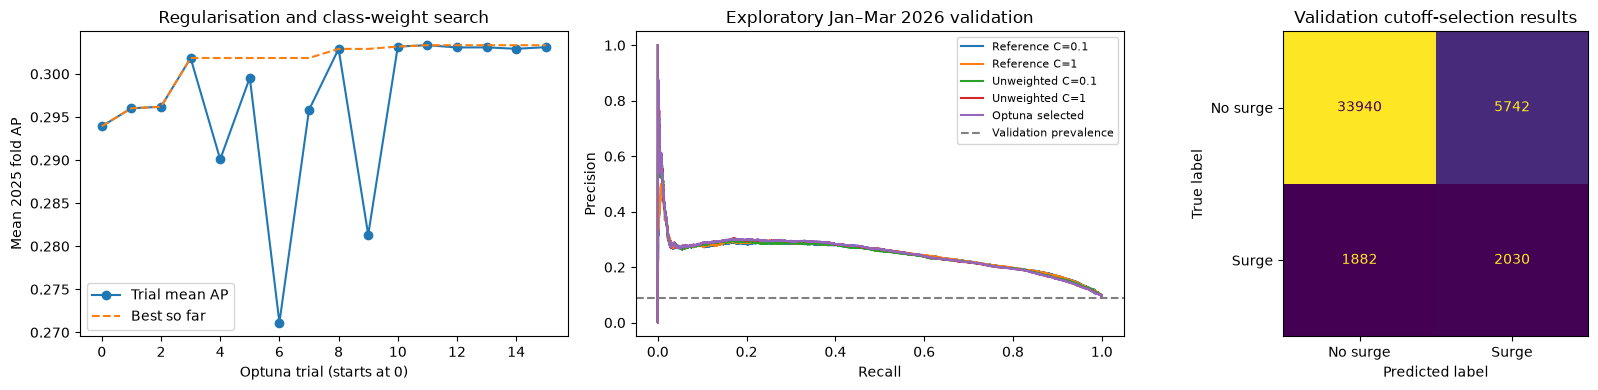

Saved Logistic Regression outputs: /Users/alfredyap/Documents/GitHub/FYP/data/runs/run_20261019_013241_618240/06_logistic_regression/20261027_092925_633674
Original models, dashboard and active-run selection were not replaced.


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ordered = trial_summary.sort_values("trial")
axes[0].plot(ordered.trial, ordered.mean_ap, "o-", label="Trial mean AP")
axes[0].plot(ordered.trial, ordered.mean_ap.cummax(), "--", label="Best so far")
axes[0].set(xlabel="Optuna trial (starts at 0)", ylabel="Mean 2025 fold AP", title="Regularisation and class-weight search")
axes[0].legend()
for label, scores in validation_scores.items():
    p, r, _ = precision_recall_curve(validation.surge_label, scores)
    axes[1].plot(r, p, label=label)
axes[1].axhline(validation.surge_label.mean(), color="grey", linestyle="--", label="Validation prevalence")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Exploratory Jan–Mar 2026 validation")
axes[1].legend(fontsize=8)
ConfusionMatrixDisplay.from_predictions(
    validation.surge_label, selected_scores >= selected_cutoff, labels=[0, 1],
    display_labels=["No surge", "Surge"], colorbar=False, ax=axes[2])
axes[2].set_title("Validation cutoff-selection results")
fig.tight_layout()
plt.show()

# Recheck exact inputs before publishing this separate result folder.
if any(file_hash(cfg.PROJECT_ROOT / name) != digest for name, digest in input_hashes.items()):
    raise ValueError("Prepared inputs changed during tuning. No completed result is published.")
stamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_%f")
OUTPUT_DIR = cfg.PROJECT_ROOT / "06_logistic_regression" / stamp
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
for filename, table in {
    "trial_fold_metrics.csv": trial_folds, "trial_summary.csv": trial_summary,
    "fold_comparison.csv": fold_comparison, "fold_summary.csv": fold_summary.reset_index(),
    "validation_comparison.csv": validation_comparison, "validation_group_metrics.csv": group_comparison,
}.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)
study.trials_dataframe().to_csv(OUTPUT_DIR / "optuna_trials.csv", index=False)
fig.savefig(OUTPUT_DIR / "tuning_and_validation.png", dpi=160, bbox_inches="tight")
# Save row identifiers for a later comparison notebook; no future prices are exported.
predictions = validation[["item_code", "state", "district", "premise_type", "project_group",
                          "week_start", "next_week_end", "surge_label"]].copy()
predictions["model_score"] = selected_scores
predictions["alert_at_05"] = selected_scores >= 0.5
predictions["alert_at_selected_cutoff"] = selected_scores >= selected_cutoff
predictions.to_parquet(OUTPUT_DIR / "validation_predictions.parquet", index=False)
joblib.dump(selected_pipeline, OUTPUT_DIR / "logistic_regression.joblib")
selection = {"family": "Logistic Regression", "parameters": {"C": BEST_C, "class_weight": BEST_CLASS_WEIGHT},
             "max_iter": MAX_ITER, "seed": SEED, "trials": N_TRIALS,
             "search": {"C": {"low": 0.001, "high": 10.0, "log": True},
                        "class_weight": [None, "balanced"]},
             "study_revision": "model-by-model workflow after 05; earlier evaluation exposure retained",
             "reference_settings": [{"method": label, "C": C, "class_weight": weight}
                                    for label, C, weight in REFERENCE_SETTINGS],
             "selection_metric": "mean AP over three expanding 2025 folds; earliest trial breaks ties",
             "selected_trial": best_trial.number, "score_cutoff": selected_cutoff,
             "cutoff_rule": "maximum Jan–Mar validation F1; highest cutoff breaks ties",
             "feature_columns": FEATURES, "surge_threshold_pct": 10.0,
             "training_end": settings["train_end"], "validation_end": settings["validation_end"],
             "refit_on_validation": False, "score_interpretation": "uncalibrated model score"}
(OUTPUT_DIR / "selection.json").write_text(json.dumps(selection, indent=2))
manifest = {"status": "completed", "study_status": "reorganised model-by-model exploratory study; test not accessed",
            "input_sha256": input_hashes, "selection": selection,
            "preparation": {name: s["preparation"] for name, s in settings_by_fold.items()},
            "package_versions": {p: metadata.version(p) for p in ["optuna", "pandas", "numpy", "scikit-learn", "joblib"]},
            "notebook_sha256": file_hash(REPOSITORY_ROOT / "06_logistic_regression.ipynb"),
            "output_sha256": {p.name: file_hash(p) for p in OUTPUT_DIR.iterdir() if p.is_file()}}
(OUTPUT_DIR / "study_manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved Logistic Regression outputs:", OUTPUT_DIR)
print("Original models, dashboard and active-run selection were not replaced.")

## 7. Use these outputs in your report

**Implementation:** explain the sigmoid/linear score, L2 regularisation, C and class weighting. Describe median imputation, numerical scaling, one-hot encoding and unseen-category handling. Explain that preprocessing and balancing use training data only, and why expanding folds respect time order. Record the 16-trial TPE budget, four reference configurations, AP objective, seed and saved package versions. Cite methodological sources for Logistic Regression and Optuna.

**Results:** use `fold_summary.csv` for mean and standard deviation of fold AP, and `fold_comparison.csv` for individual folds. Compare the original references, unweighted references, Optuna candidate and simple baselines. Include `trial_summary.csv` and the search-history plot to explain what was investigated, including repeated configurations. A higher maximum search score is not an independent improvement estimate.

**Later validation:** report AP, then precision, recall, F1, false alerts and missed surges. Distinguish the common 0.5 reference from the validation-selected cutoff. The latter maximises F1 on the displayed validation period, so those metrics are apparent cutoff-selection results, not a new test. A lower cutoff can improve recall by issuing more alerts. AP and fixed-cutoff F1 can move differently, particularly when class weighting changes.

**Food groups:** use `validation_group_metrics.csv` to report positive support and detection by group. Do not let overall vegetable-dominated results imply dependable detection of every food group. Undefined positive-case metrics are left missing. The score is uncalibrated and the cutoff is not a percentage price increase.

**Evidence and comparison:** `selection.json` records selected parameters and cutoff; `study_manifest.json` records input/output hashes and versions. `validation_predictions.parquet` saves identifiers, observed labels and scores for matching rows across later model notebooks. It contains no next-week prices. Compare identical input hashes, time periods and eligible rows; matching dates or row counts alone is insufficient. The figure includes tuning history, validation precision–recall curves and a confusion matrix.

**Conclusion:** state whether tuning helped the reused folds and later validation, including small or negative effects. Do not automatically replace a dashboard model or assign another model's test scores to this candidate. Restarting preparation does not erase earlier exposure. A new final performance claim needs a genuinely untouched period and a frozen protocol.

The historical multi-model experiment remains in `06_model_training_and_evaluation.ipynb`; it is not a prerequisite for this notebook. The previous Logistic Regression research study remains historical evidence. Anomaly detection, SHAP and dashboard integration are separate later tasks; this notebook completes the first classifier only.